# Week 2 — Exploratory Data Analysis: NextGenLearners Applicant Insights

 ## Step 1: Set Up 

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
df = pd.read_csv(r"D:\NextGen Intern\applicants_cleaned dataset.csv", parse_dates = ['Application Date'])

In [9]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    72 non-null     object        
 1   Email             72 non-null     object        
 2   Phone             72 non-null     int64         
 3   Domain Applied    72 non-null     object        
 4   University        72 non-null     object        
 5   Application Date  72 non-null     datetime64[ns]
 6   Status            72 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.1+ KB


In [10]:
df.head() 

,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ayesha Malik,ayesha.malik01@gmail.com,3113356886,Web Development,Bahria University,2026-04-20,Under Review
1,Ali Khan,ali.khan02@outlook.com,3442868828,Data Science,University of Punjab,2026-01-26,Rejected
2,Hassan Raza,hassan.raza03@yahoo.com,3328728463,UI/UX Design,Air University,2026-04-26,Selected
3,Fatima Noor,fatima.noor04@example.com,3183197857,Mobile App Development,University of Lahore,2026-01-26,Selected
4,Usman Tariq,usman.tariq05@gmail.com,3189254563,Artificial Intelligence,Bahria University,2026-05-02,Under Review


In [11]:
## Step 2: Which Domain Received the Most Applications?

In [12]:
domain_counts = df['Domain Applied'].value_counts() 
print(domain_counts)

Domain Applied
Data Science               16
UI/UX Design               15
Artificial Intelligence    15
Web Development            13
Mobile App Development     13
Name: count, dtype: int64


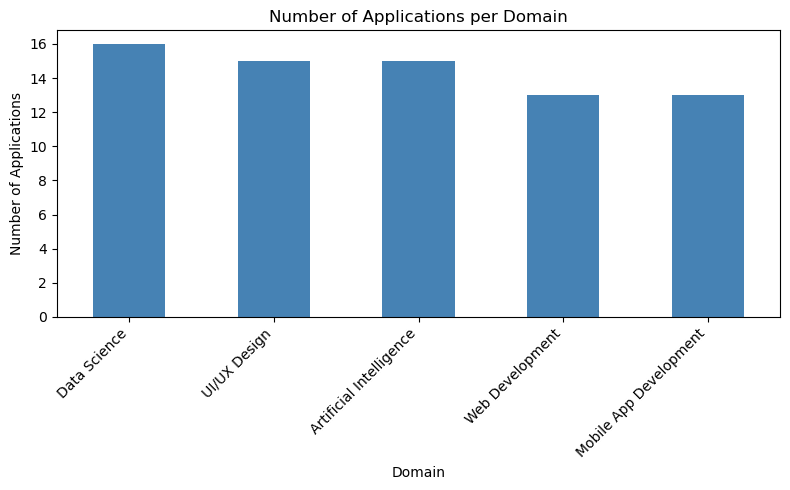

In [13]:
## The visualization (a bar chart):

plt.figure(figsize=(8,5)) 
domain_counts.plot(kind='bar', color='steelblue') 
plt.title('Number of Applications per Domain') 
plt.xlabel('Domain') 
plt.ylabel('Number of Applications') 
plt.xticks(rotation=45, ha='right') 
plt.tight_layout() 
plt.show() 

 "Data Science received
the highest number of applications (16),The lowest domain is app development (14)." 

## Step 4: How Did Applications Trend Over Time?

In [14]:
##  Group by month 

df['Application Month'] = df['Application Date'].dt.to_period('M') 
monthly_trend = df.groupby('Application Month').size() 
print(monthly_trend) 

Application Month
2026-01    31
2026-04     7
2026-05    15
2026-06    11
2026-07     6
2026-10     1
2026-11     1
Freq: M, dtype: int64


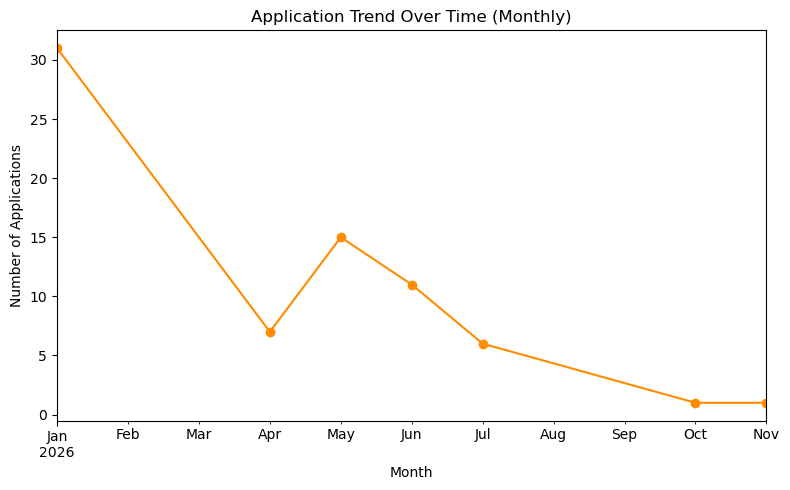

In [15]:
## The visualization (a line chart, ideal for trends over time): 


plt.figure(figsize=(8,5)) 
monthly_trend.plot(kind='line', marker='o', color='darkorange') 
plt.title('Application Trend Over Time (Monthly)') 
plt.xlabel('Month') 
plt.ylabel('Number of Applications') 
plt.tight_layout() 
plt.show() 

 "Applications spiked in January 2026, then directly decrease in April and then increase in May and then gradually decrease toward the application deadline."

## Step 5: What's the Acceptance Rate — Overall and Per Domain?

In [16]:
## Overall status breakdown: 

status_counts = df['Status'].value_counts() 
print(status_counts)

Status
Selected        26
Rejected        24
Under Review    22
Name: count, dtype: int64


In [17]:
## Per-domain breakdown using pivot_table(): 

status_by_domain = pd.pivot_table( 
    df, 
    index='Domain Applied', 
    columns='Status', 
    values='Applicant Name', 
    aggfunc='count', 
    fill_value=0 
) 
print(status_by_domain)

Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence         7         5             3
Data Science                    5         6             5
Mobile App Development          5         4             4
UI/UX Design                    3         7             5
Web Development                 4         4             5


In [18]:
## Calculate acceptance rate (percentage), not just raw counts: 

status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), 
axis=0) * 100 
print(status_by_domain_pct.round(1)) 

Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence      46.7      33.3          20.0
Data Science                 31.2      37.5          31.2
Mobile App Development       38.5      30.8          30.8
UI/UX Design                 20.0      46.7          33.3
Web Development              30.8      30.8          38.5


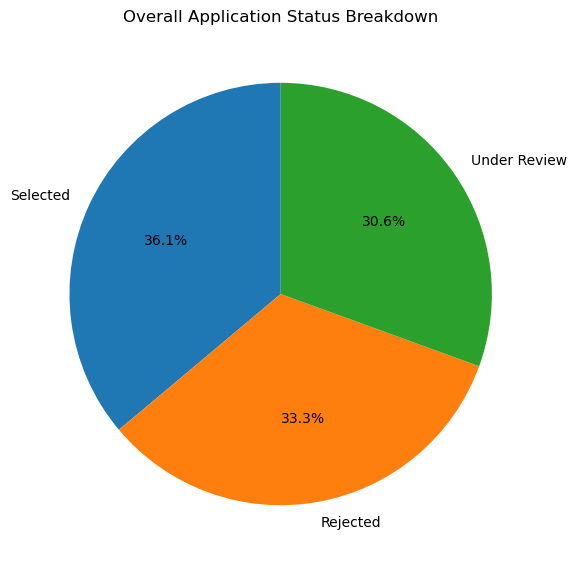

In [19]:
## The visualization (a pie chart for overall status
# Overall status - pie chart

plt.figure(figsize=(6,6)) 
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90) 
plt.title('Overall Application Status Breakdown') 
plt.ylabel('')  # removes the default awkward y-label pie charts add 
plt.tight_layout() 
plt.show()

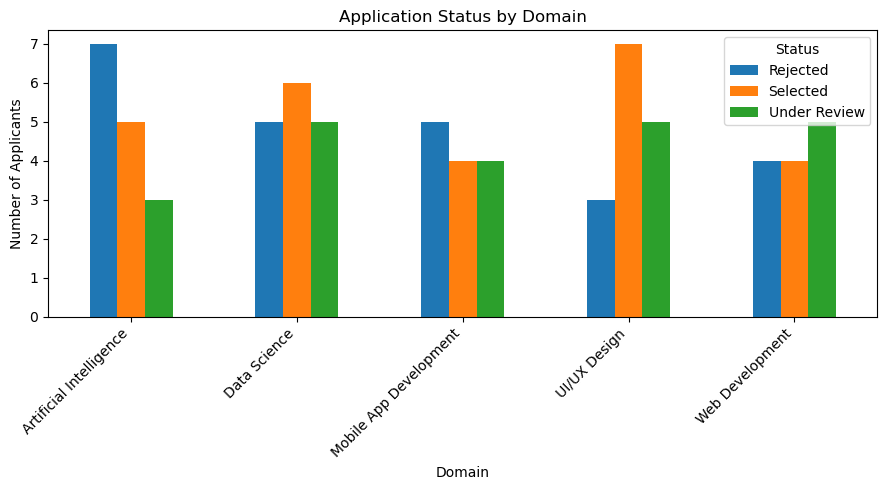

In [20]:
## Per-domain - grouped bar chart


status_by_domain.plot(kind='bar', figsize=(9,5)) 
plt.title('Application Status by Domain') 
plt.xlabel('Domain') 
plt.ylabel('Number of Applicants') 
plt.xticks(rotation=45, ha='right') 
plt.legend(title='Status') 
plt.tight_layout() 
plt.show() 

In [21]:
print(df["Status"].value_counts())

Status
Selected        26
Rejected        24
Under Review    22
Name: count, dtype: int64


In [22]:
print(status_by_domain)

Status                   Rejected  Selected  Under Review
Domain Applied                                           
Artificial Intelligence         7         5             3
Data Science                    5         6             5
Mobile App Development          5         4             4
UI/UX Design                    3         7             5
Web Development                 4         4             5


### Takeaway

The most common application status was Selected, with 26 applicants. 
Among the domain the UI/UX design had the highest number of selected applicants(7)

## Step 6: Which Universities Sent the Most Applicants?

In [23]:
## The aggregation: 

top_universities = df['University'].value_counts().head(10) 
print(top_universities)

University
Bahria University                              18
University of Punjab                           18
University of Lahore                           16
Air University                                 14
Not Specified                                   3
University of Peshawar                          1
National University of Science & Technology     1
University of Malakand                          1
Name: count, dtype: int64


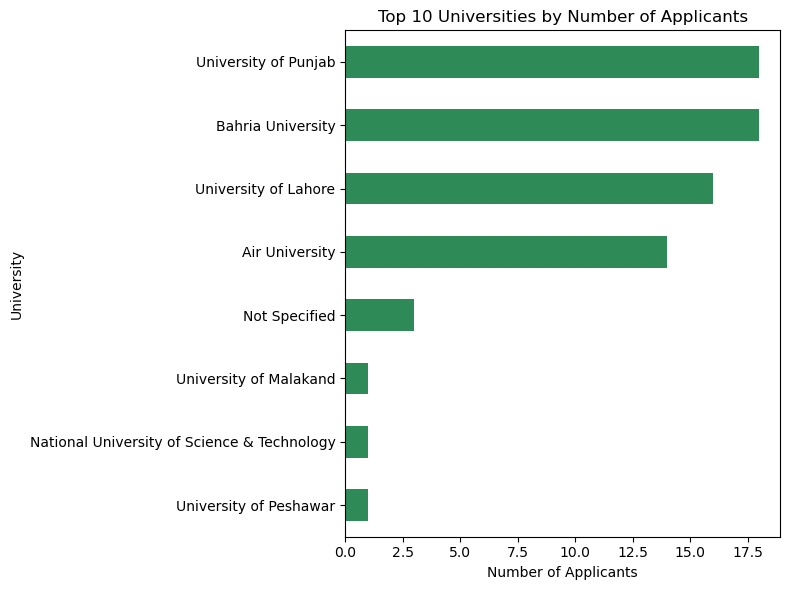

In [24]:
## The visualization(horizonatal bar chart):

plt.figure(figsize=(8,6)) 
top_universities.sort_values().plot(kind='barh', color='seagreen') 
plt.title('Top 10 Universities by Number of Applicants') 
plt.xlabel('Number of Applicants') 
plt.ylabel('University') 
plt.tight_layout() 
plt.show() 

## Step 7: Your Own Bonus Chart (Required — Your Choice)

Application Day
Monday       37
Tuesday       9
Wednesday     6
Thursday      4
Friday        6
Saturday      5
Sunday        5
Name: count, dtype: int64


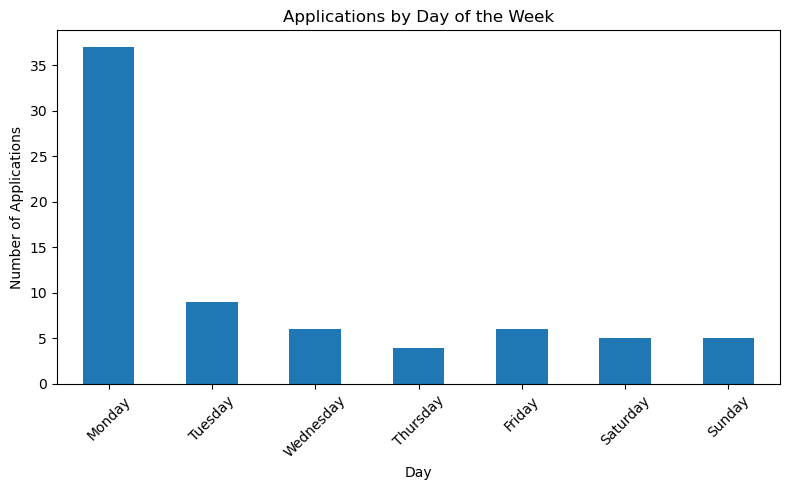

In [4]:
df["Application Day"] = (
    df["Application Date"].dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_counts = (
    df["Application Day"].value_counts().reindex(day_order, fill_value=0)
)

print(day_counts)

day_counts.plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Applications by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 8: Write the "Key Insights" Section

## Key Insights
- Data Science Domain  received the highest number of applicant with 16 applicants.
- Applications were highest in january 2026, with 31 applications.
- The most common application status was Selected, representing 36.1% of applicants
- Bahria and University of the punajab contributed the highest number of applicants, with 18 applicants.
- Monday has the highest number of applications, suggesting that this was the busiest application day in the dataset.